In [3]:
import pandas as pd
import os

# Find the training file by its original filename
train_file = [f for f in os.listdir("/content") if f.endswith("train.csv")][0]

# Load the data
train_df = pd.read_csv("/content/" + train_file)

# Display the first five rows
train_df.head()

,request_id,created_at_ist,channel,product_family,warranty_status,request_text,source,team_label
0,SR500000,2025-04-01 00:31,whatsapp,Robot Vacuum,shield,sir how to clean robot vacuum reg no SR75294,legacy_zoho,Product Advice
1,SR500001,2025-04-01 01:27,chat,Water Purifier,out_of_warranty,"hello team, emi conversion not done for purifi...",legacy_zoho,Billing
2,SR500002,2025-04-01 03:26,whatsapp,Water Purifier,in_warranty,claim status for purifier under warranty paid ...,legacy_zoho,Billing
3,SR500003,2025-04-01 04:50,chat,Robot Vacuum,in_warranty,sir spare blade set for fan available? asap,legacy_zoho,Consumables
4,SR500004,2025-04-01 06:39,ivr,Air Fryer,out_of_warranty,"hi, display of air fryer gone blank thanks",legacy_zoho,Repairs


In [4]:
# How many rows and columns?
print("Dataset shape:", train_df.shape)

# What are the column names and data types?
train_df.info()

# Are any values missing?
print("\nMissing values:")
print(train_df.isnull().sum())

# How many examples belong to each team?
print("\nRequests per team:")
print(train_df["team_label"].value_counts())

Dataset shape: (10822, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10822 entries, 0 to 10821
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   request_id       10822 non-null  object
 1   created_at_ist   10822 non-null  object
 2   channel          10822 non-null  object
 3   product_family   10822 non-null  object
 4   warranty_status  10822 non-null  object
 5   request_text     10822 non-null  object
 6   source           10822 non-null  object
 7   team_label       10822 non-null  object
dtypes: object(8)
memory usage: 676.5+ KB

Missing values:
request_id         0
created_at_ist     0
channel            0
product_family     0
warranty_status    0
request_text       0
source             0
team_label         0
dtype: int64

Requests per team:
team_label
Repairs                  3129
Billing                  1656
Product Advice           1180
Returns & Replacement    1174
Warranty Claims          

In [5]:
# Check whether request IDs are duplicated
print("Duplicate request IDs:",
      train_df["request_id"].duplicated().sum())

# Check for completely duplicated rows
print("Duplicate rows:",
      train_df.duplicated().sum())

# Inspect examples from each team
for team in sorted(train_df["team_label"].unique()):
    print(f"\n--- {team} ---")

    examples = train_df.loc[
        train_df["team_label"] == team,
        "request_text"
    ].head(3)

    for text in examples:
        print("-", text)

Duplicate request IDs: 0
Duplicate rows: 0

--- Billing ---
- hello team, emi conversion not done for purifier, coupon discount not applied on purifier thanks
- claim status for purifier under warranty paid by emi very disappointed Ã¢â‚¬Â¦
- sir coupon discount not applied on cooktop

--- Consumables ---
- sir spare blade set for fan available? asap
- urgent: where to buy spare jar for robot vacuum very disappointed
- urgent: spare blade set for mixer grinder available?

--- Filters & Consumables ---
- want AMC filter kit for room heater order KO2605107
- urgent: water purifier showing error code E2 very disappointed
- hello team, where to buy spare jar for induction cooktop reg no SR29701

--- Installations ---
- urgÃ©nt: installer did not turn up for room heater asap
- pls help - installation slot for fryer not confirmed, installer did not turn up for fryer kindly resolve
- urgent: need installation for my new water purifier order KO2604104

--- Installs & Demo ---
- pls help - water

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# Input text and target labels
X = train_df["request_text"]
y = train_df["team_label"]

# Keep a portion aside for evaluation
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Build the baseline pipeline
model = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2))),
    ("classifier", LogisticRegression(max_iter=1000))
])

# Train the model
model.fit(X_train, y_train)

# Evaluate on the held-out examples
y_pred = model.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("\nClassification report:")
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy: 0.8448

Classification report:
                       precision    recall  f1-score   support

              Billing       0.93      0.97      0.95       331
          Consumables       0.58      0.76      0.66       186
Filters & Consumables       0.19      0.03      0.05       106
        Installations       0.59      0.81      0.68       149
      Installs & Demo       0.32      0.08      0.13        88
       Product Advice       0.93      0.96      0.94       236
              Repairs       0.92      0.94      0.93       626
Returns & Replacement       0.94      0.94      0.94       235
      Warranty Claims       0.95      0.98      0.96       208

             accuracy                           0.84      2165
            macro avg       0.70      0.72      0.69      2165
         weighted avg       0.81      0.84      0.82      2165



In [7]:
# Convert the timestamp column into a proper datetime type
train_df["created_at_ist"] = pd.to_datetime(
    train_df["created_at_ist"],
    errors="coerce"
)

# Inspect the date range
print("Earliest request:", train_df["created_at_ist"].min())
print("Latest request:", train_df["created_at_ist"].max())

# Compare team labels before and after the stated rename date
rename_date = pd.Timestamp("2026-01-15")

train_df["period"] = train_df["created_at_ist"].apply(
    lambda date: "Before rename"
    if date < rename_date
    else "On/after rename"
)

print("\nCounts by period and team:")
print(pd.crosstab(train_df["period"], train_df["team_label"]))

Earliest request: 2025-04-01 00:31:00
Latest request: 2026-06-30 23:33:00

Counts by period and team:
team_label       Billing  Consumables  Filters & Consumables  Installations  \
period                                                                        
Before rename       1034          927                      0            745   
On/after rename      622            0                    531              0   

team_label       Installs & Demo  Product Advice  Repairs  \
period                                                      
Before rename                  0             760     1999   
On/after rename              440             420     1130   

team_label       Returns & Replacement  Warranty Claims  
period                                                   
Before rename                      718              675  
On/after rename                    456              365  


In [8]:
# Keep the original data unchanged
train_standardized = train_df.copy()

# Standardize historical team names to current names
team_mapping = {
    "Consumables": "Filters & Consumables",
    "Installations": "Installs & Demo"
}

train_standardized["team_label"] = (
    train_standardized["team_label"].replace(team_mapping)
)

# Check the new label counts
print("Number of standardized teams:",
      train_standardized["team_label"].nunique())

print("\nStandardized label counts:")
print(train_standardized["team_label"].value_counts())

Number of standardized teams: 7

Standardized label counts:
team_label
Repairs                  3129
Billing                  1656
Filters & Consumables    1458
Installs & Demo          1185
Product Advice           1180
Returns & Replacement    1174
Warranty Claims          1040
Name: count, dtype: int64


In [9]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# Inputs and standardized target labels
X = train_standardized["request_text"]
y = train_standardized["team_label"]

# Create a reproducible train/test split
X_train_std, X_test_std, y_train_std, y_test_std = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Build the model
model_std = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2))),
    ("classifier", LogisticRegression(max_iter=1000))
])

# Train and predict
model_std.fit(X_train_std, y_train_std)
y_pred_std = model_std.predict(X_test_std)

# Evaluate
print("Standardized-label accuracy:",
      round(accuracy_score(y_test_std, y_pred_std), 4))

print("\nClassification report:")
print(classification_report(
    y_test_std,
    y_pred_std,
    zero_division=0
))

Standardized-label accuracy: 0.9344

Classification report:
                       precision    recall  f1-score   support

              Billing       0.93      0.96      0.95       331
Filters & Consumables       0.91      0.84      0.88       292
      Installs & Demo       0.95      0.96      0.95       237
       Product Advice       0.94      0.94      0.94       236
              Repairs       0.94      0.93      0.94       626
Returns & Replacement       0.92      0.97      0.94       235
      Warranty Claims       0.95      0.95      0.95       208

             accuracy                           0.93      2165
            macro avg       0.93      0.94      0.94      2165
         weighted avg       0.93      0.93      0.93      2165



In [10]:
# Find and load the unlabeled test file
test_file = [
    f for f in os.listdir("/content")
    if f.endswith("test_unlabelled.csv")
][0]

test_df = pd.read_csv("/content/" + test_file)

print("Test dataset shape:", test_df.shape)
print("\nColumns:")
print(test_df.columns.tolist())

print("\nMissing values:")
print(test_df.isnull().sum())

print("\nFirst five rows:")
display(test_df.head())

Test dataset shape: (2178, 7)

Columns:
['request_id', 'created_at_ist', 'channel', 'product_family', 'warranty_status', 'request_text', 'source']

Missing values:
request_id         0
created_at_ist     0
channel            0
product_family     0
warranty_status    0
request_text       0
source             0
dtype: int64

First five rows:


,request_id,created_at_ist,channel,product_family,warranty_status,request_text,source
0,SR510822,2026-07-01 00:31,chat,Air Fryer,in_warranty,display of air fryer gone blank pls call back,crm
1,SR510823,2026-07-01 02:01,chat,Air Fryer,shield,"good morning, want AMC filter kit for air frye...",crm
2,SR510824,2026-07-01 03:07,ivr,Water Purifier,in_warranty,sir water purifier leaking water from bottom p...,crm
3,SR510825,2026-07-01 04:56,email,Robot Vacuum,in_warranty,"hi, installer did not turn up for cooktop i pa...",crm
4,SR510826,2026-07-01 05:13,chat,Mixer Grinder,in_warranty,"good morning, installation slot for mixer grin...",crm


In [11]:
# Predict the support team for each test request
test_predictions = model_std.predict(test_df["request_text"])

# Build the submission in the required format
submission = pd.DataFrame({
    "request_id": test_df["request_id"],
    "team": test_predictions
})

# Inspect the result
print("Submission shape:", submission.shape)
print("\nPredicted team counts:")
print(submission["team"].value_counts())

display(submission.head(10))

Submission shape: (2178, 2)

Predicted team counts:
team
Repairs                  640
Billing                  345
Filters & Consumables    274
Returns & Replacement    244
Installs & Demo          241
Product Advice           230
Warranty Claims          204
Name: count, dtype: int64


,request_id,team
0,SR510822,Repairs
1,SR510823,Filters & Consumables
2,SR510824,Filters & Consumables
3,SR510825,Billing
4,SR510826,Installs & Demo
5,SR510827,Installs & Demo
6,SR510828,Installs & Demo
7,SR510829,Installs & Demo
8,SR510830,Installs & Demo
9,SR510831,Repairs


In [12]:
submission.to_csv("/content/submission.csv", index=False)
print("Saved submission.csv")

Saved submission.csv


In [13]:
from google.colab import files
files.download("/content/submission.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [14]:
import pandas as pd

# Get class probabilities from the trained model
probabilities = model_std.predict_proba(test_df["request_text"])

# Find the highest probability for each prediction
submission_review = submission.copy()
submission_review["confidence"] = probabilities.max(axis=1)
submission_review["request_text"] = test_df["request_text"]

# Show the 15 least-confident predictions
display(
    submission_review
    .sort_values("confidence")
    [["request_id", "request_text", "team", "confidence"]]
    .head(15)
)

,request_id,request_text,team,confidence
1681,SR512503,sir spare blade set for mixer grinder availabl...,Repairs,0.363451
131,SR510953,"hi, wrong model of machine delivered, extend w...",Returns & Replacement,0.418314
1050,SR511872,"namaste, difference between lite and pro ceili...",Billing,0.420869
1350,SR512172,"sir which machine is right for 4 people, issue...",Repairs,0.425241
23,SR510845,"hello team, warranty rejected for air fryer, w...",Product Advice,0.434720
532,SR511354,"good morning, when will the technician come to...",Installs & Demo,0.435826
118,SR510940,"sir received used air fryer, want exchange, wa...",Warranty Claims,0.436775
1213,SR512035,"want AMC filter kit for fryer, fryer tripping ...",Filters & Consumables,0.441003
1157,SR511979,"namaste, received used mixer grinder, want exc...",Returns & Replacement,0.443247
113,SR510935,"pls help - how to clean water purifier, box wa...",Returns & Replacement,0.443347


In [15]:
# Select the 15 least-confident predictions
uncertain = (
    submission_review
    .sort_values("confidence")
    .head(15)
)

# Print each case without table truncation
for _, row in uncertain.iterrows():
    print("-" * 70)
    print("Request ID:", row["request_id"])
    print("Message:", row["request_text"])
    print("Predicted team:", row["team"])
    print("Confidence:", round(row["confidence"], 3))

----------------------------------------------------------------------
Request ID: SR512503
Message: sir spare blade set for mixer grinder available?, please call back regarding mixer grinder paid on upi
Predicted team: Repairs
Confidence: 0.363
----------------------------------------------------------------------
Request ID: SR510953
Message: hi, wrong model of machine delivered, extend warranty for machine thanks
Predicted team: Returns & Replacement
Confidence: 0.418
----------------------------------------------------------------------
Request ID: SR511872
Message: namaste, difference between lite and pro ceiling fan, want to return the ceiling fan paid on upi pls call back
Predicted team: Billing
Confidence: 0.421
----------------------------------------------------------------------
Request ID: SR512172
Message: sir which machine is right for 4 people, issue with machine order KO2600091 asap
Predicted team: Repairs
Confidence: 0.425
----------------------------------------------

In [16]:
import numpy as np

# Get the 3 most likely teams for every test request
probabilities = model_std.predict_proba(test_df["request_text"])
classes = model_std.named_steps["classifier"].classes_

top3_indices = np.argsort(probabilities, axis=1)[:, -3:][:, ::-1]

# Print alternatives for the uncertain examples
for idx in uncertain.index:
    row_position = submission.index.get_loc(idx)
    print("-" * 60)
    print("Request:", test_df.iloc[row_position]["request_id"])
    print("Message:", test_df.iloc[row_position]["request_text"])

    for class_idx in top3_indices[row_position]:
        print(
            f"  {classes[class_idx]}: "
            f"{probabilities[row_position, class_idx]:.3f}"
        )

------------------------------------------------------------
Request: SR512503
Message: sir spare blade set for mixer grinder available?, please call back regarding mixer grinder paid on upi
  Repairs: 0.363
  Filters & Consumables: 0.309
  Billing: 0.290
------------------------------------------------------------
Request: SR510953
Message: hi, wrong model of machine delivered, extend warranty for machine thanks
  Returns & Replacement: 0.418
  Warranty Claims: 0.412
  Billing: 0.059
------------------------------------------------------------
Request: SR511872
Message: namaste, difference between lite and pro ceiling fan, want to return the ceiling fan paid on upi pls call back
  Billing: 0.421
  Product Advice: 0.288
  Returns & Replacement: 0.204
------------------------------------------------------------
Request: SR512172
Message: sir which machine is right for 4 people, issue with machine order KO2600091 asap
  Repairs: 0.425
  Product Advice: 0.424
  Filters & Consumables: 0.07

In [17]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report

# Use the same split as before
X = train_standardized[
    ["request_text", "product_family", "channel", "warranty_status"]
]
y = train_standardized["team_label"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Process text and categorical columns differently
preprocessor = ColumnTransformer([
    ("text", TfidfVectorizer(ngram_range=(1, 2)), "request_text"),
    (
        "categories",
        OneHotEncoder(handle_unknown="ignore"),
        ["product_family", "channel", "warranty_status"]
    )
])

model_features = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

model_features.fit(X_train, y_train)
pred_features = model_features.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, pred_features), 4))
print(classification_report(y_test, pred_features, zero_division=0))

Accuracy: 0.9478
                       precision    recall  f1-score   support

              Billing       0.94      0.96      0.95       331
Filters & Consumables       0.93      0.93      0.93       292
      Installs & Demo       0.94      0.95      0.95       237
       Product Advice       0.95      0.94      0.95       236
              Repairs       0.98      0.94      0.96       626
Returns & Replacement       0.92      0.96      0.94       235
      Warranty Claims       0.94      0.96      0.95       208

             accuracy                           0.95      2165
            macro avg       0.94      0.95      0.95      2165
         weighted avg       0.95      0.95      0.95      2165



In [18]:
# Train the selected model on all labelled data
X_all = train_standardized[
    ["request_text", "product_family", "channel", "warranty_status"]
]
y_all = train_standardized["team_label"]

model_features.fit(X_all, y_all)

# Prepare the same input columns from the unlabeled test data
X_unlabelled = test_df[
    ["request_text", "product_family", "channel", "warranty_status"]
]

# Predict teams
final_predictions = model_features.predict(X_unlabelled)

# Create the required submission
final_submission = pd.DataFrame({
    "request_id": test_df["request_id"],
    "team": final_predictions
})

print("Submission shape:", final_submission.shape)
print("\nPredicted team counts:")
print(final_submission["team"].value_counts())

display(final_submission.head())

Submission shape: (2178, 2)

Predicted team counts:
team
Repairs                  631
Billing                  341
Filters & Consumables    285
Installs & Demo          244
Returns & Replacement    242
Product Advice           228
Warranty Claims          207
Name: count, dtype: int64


,request_id,team
0,SR510822,Repairs
1,SR510823,Filters & Consumables
2,SR510824,Filters & Consumables
3,SR510825,Billing
4,SR510826,Installs & Demo


In [19]:
# Find and load the resolution log
resolution_file = [
    f for f in os.listdir("/content")
    if f.endswith("resolution_log.csv")
][0]

resolution_df = pd.read_csv("/content/" + resolution_file)

print("Resolution log shape:", resolution_df.shape)
print("\nColumns:")
print(resolution_df.columns.tolist())

print("\nFirst five rows:")
display(resolution_df.head())

print("\nSummary statistics:")
display(resolution_df.describe(include="all"))

Resolution log shape: (10822, 5)

Columns:
['request_id', 'first_team', 'final_team', 'transfers', 'resolved_at']

First five rows:


,request_id,first_team,final_team,transfers,resolved_at
0,SR500000,Product Advice,Product Advice,0,2025-04-01 11:04
1,SR500001,Billing,Billing,0,2025-03-31 22:41
2,SR500002,Billing,Warranty Claims,1,2025-04-01 13:26
3,SR500003,Consumables,Consumables,0,2025-04-01 11:07
4,SR500004,Repairs,Repairs,1,2025-04-01 09:18



Summary statistics:


,request_id,first_team,final_team,transfers,resolved_at
count,10822,10822,10822,10822.000000,10822
unique,10822,9,9,NaN,10736
top,SR510821,Repairs,Repairs,NaN,2026-04-11 06:21
freq,1,3129,2534,NaN,2
mean,NaN,NaN,NaN,0.360562,NaN
std,NaN,NaN,NaN,0.673408,NaN
min,NaN,NaN,NaN,0.000000,NaN
25%,NaN,NaN,NaN,0.000000,NaN
50%,NaN,NaN,NaN,0.000000,NaN
75%,NaN,NaN,NaN,0.000000,NaN


In [20]:
# Total transfer events
total_transfers = resolution_df["transfers"].sum()

# Requests that ended with a different team than the first team
misrouted_requests = (
    resolution_df["first_team"] != resolution_df["final_team"]
).sum()

# Requests with at least one transfer
requests_transferred = (
    resolution_df["transfers"] > 0
).sum()

# Costs based on the assignment's assumptions
transfer_cost = total_transfers * 305
extra_contact_cost = misrouted_requests * 260

print("Total requests:", len(resolution_df))
print("Total transfer events:", total_transfers)
print("Requests with at least one transfer:", requests_transferred)
print("Requests where first and final teams differ:", misrouted_requests)
print(f"Historical transfer cost: ₹{transfer_cost:,.0f}")
print(f"Estimated extra contact cost: ₹{extra_contact_cost:,.0f}")
print(f"Combined estimated cost: ₹{transfer_cost + extra_contact_cost:,.0f}")

Total requests: 10822
Total transfer events: 3902
Requests with at least one transfer: 2696
Requests where first and final teams differ: 2471
Historical transfer cost: ₹1,190,110
Estimated extra contact cost: ₹642,460
Combined estimated cost: ₹1,832,570


In [21]:
# Count requests that started in each team
first_team_counts = resolution_df["first_team"].value_counts()

# Count requests that ended in a different team
changed_team = resolution_df[
    resolution_df["first_team"] != resolution_df["final_team"]
]

# How often each initial team had a different final team
misroutes_by_team = (
    changed_team["first_team"]
    .value_counts()
    .rename("changed_to_different_team")
)

# Combine the counts
team_analysis = pd.DataFrame({
    "requests_started": first_team_counts,
    "ended_in_different_team": misroutes_by_team
}).fillna(0)

team_analysis["ended_in_different_team"] = (
    team_analysis["ended_in_different_team"].astype(int)
)

team_analysis["different_team_rate_pct"] = (
    team_analysis["ended_in_different_team"]
    / team_analysis["requests_started"] * 100
).round(1)

team_analysis = team_analysis.sort_values(
    "different_team_rate_pct", ascending=False
)

display(team_analysis)

,requests_started,ended_in_different_team,different_team_rate_pct
first_team,,,
Consumables,927,381,41.1
Filters & Consumables,531,205,38.6
Repairs,3129,1136,36.3
Billing,1656,585,35.3
Product Advice,1180,45,3.8
Warranty Claims,1040,38,3.7
Returns & Replacement,1174,42,3.6
Installations,745,25,3.4
Installs & Demo,440,14,3.2


In [22]:
# Historical costs from the resolution log
transfer_cost_per_event = 305
extra_contact_cost_per_changed_request = 260

baseline_transfer_cost = total_transfers * transfer_cost_per_event
baseline_contact_cost = misrouted_requests * extra_contact_cost_per_changed_request
baseline_combined_cost = baseline_transfer_cost + baseline_contact_cost

# Hypothetical reductions in transfer events and changed-team requests
scenarios = [0.10, 0.20, 0.30, 0.40]

scenario_results = []

for reduction in scenarios:
    saved_transfer_cost = baseline_transfer_cost * reduction
    saved_contact_cost = baseline_contact_cost * reduction

    scenario_results.append({
        "assumed_reduction_pct": int(reduction * 100),
        "estimated_transfer_savings_INR": round(saved_transfer_cost),
        "estimated_contact_savings_INR": round(saved_contact_cost),
        "estimated_total_savings_INR": round(
            saved_transfer_cost + saved_contact_cost
        )
    })

scenario_df = pd.DataFrame(scenario_results)
display(scenario_df)


,assumed_reduction_pct,estimated_transfer_savings_INR,estimated_contact_savings_INR,estimated_total_savings_INR
0,10,119011,64246,183257
1,20,238022,128492,366514
2,30,357033,192738,549771
3,40,476044,256984,733028


In [23]:
scenario_df = pd.DataFrame(scenario_results)

# Format the percentage as a readable percentage value
scenario_df["assumed_reduction_pct"] = (
    scenario_df["assumed_reduction_pct"].astype(str) + "%"
)

display(scenario_df.reset_index(drop=True))

,assumed_reduction_pct,estimated_transfer_savings_INR,estimated_contact_savings_INR,estimated_total_savings_INR
0,10%,119011,64246,183257
1,20%,238022,128492,366514
2,30%,357033,192738,549771
3,40%,476044,256984,733028


In [24]:
# Create a clean display copy
display_df = scenario_df.reset_index(drop=True).copy()

# Ensure the percentage column has the intended values
display_df["assumed_reduction_pct"] = [10, 20, 30, 40]

# Set the percentage column as the table's index
display_df = display_df.set_index("assumed_reduction_pct")
display_df.index.name = "Assumed reduction (%)"

display(display_df)

,estimated_transfer_savings_INR,estimated_contact_savings_INR,estimated_total_savings_INR
Assumed reduction (%),,,
10,119011,64246,183257
20,238022,128492,366514
30,357033,192738,549771
40,476044,256984,733028


In [25]:
# View test requests predicted as Billing
billing_cases = test_df.loc[
    final_predictions == "Billing",
    ["request_id", "product_family", "request_text"]
]

display(billing_cases.head(20))

,request_id,product_family,request_text
3,SR510825,Robot Vacuum,"hi, installer did not turn up for cooktop i pa..."
15,SR510837,Ceiling Fan,"namaste, coupon discount not applied on ceilin..."
22,SR510844,Air Fryer,"emi conversion not done for air fryer, coupon ..."
27,SR510849,Room Heater,"namaste, claim status for heater under warrant..."
52,SR510874,Mixer Grinder,pls help - want to reschedule installation of ...
54,SR510876,Air Fryer,urgent: coupon discount not applied on machine...
61,SR510883,Air Fryer,"hi, refund not credited for cancelled machine ..."
69,SR510891,Induction Cooktop,urgent: cooktop leaking water from bottom paym...
73,SR510895,Induction Cooktop,"hello team, invoice not received for induction..."
78,SR510900,Room Heater,"hello team, gst invoice wrong name for room he..."


In [26]:
# Find Billing predictions that may actually be service-related
billing_audit = test_df.loc[
    final_predictions == "Billing",
    ["request_id", "product_family", "request_text"]
].copy()

billing_audit["predicted_team"] = "Billing"

service_terms = r"install|installer|repair|breakdown|not working|warranty|leak|technician|reschedule"

possible_misroutes = billing_audit[
    billing_audit["request_text"].str.contains(
        service_terms, case=False, regex=True, na=False
    )
]

pd.set_option("display.max_colwidth", None)
display(
    possible_misroutes[
        ["request_id", "product_family", "request_text", "predicted_team"]
    ].head(25)
)

,request_id,product_family,request_text,predicted_team
3,SR510825,Robot Vacuum,"hi, installer did not turn up for cooktop i paid extra for this thanks",Billing
27,SR510849,Room Heater,"namaste, claim status for heater under warranty paid via card kindly resolve",Billing
52,SR510874,Mixer Grinder,pls help - want to reschedule installation of mixer grinder i paid extra for this asap,Billing
69,SR510891,Induction Cooktop,urgent: cooktop leaking water from bottom payment done,Billing
81,SR510903,Water Purifier,"hi, installer did not turn up for water purifier paid by emi very disappointed",Billing
202,SR511024,Induction Cooktop,"good morning, installation slot for induction cooktop not confirmed paid by emi pls call back",Billing
459,SR511281,Air Fryer,"hello team, need installation for my new air fryer payment done order KO2610350",Billing
521,SR511343,Water Purifier,"hello team, water purifier delivered but not installed yet i paid extra for this order KO2604547",Billing
525,SR511347,Mixer Grinder,"hello team, installer did not turn up for product paid on upi reg no SR20163",Billing
531,SR511353,Air Fryer,"good morning, installer did not turn up for air fryer already paid in full asap",Billing


In [27]:
# Work with all test requests predicted as Billing
billing_audit = test_df.loc[
    final_predictions == "Billing",
    ["request_id", "product_family", "request_text"]
].copy()

text = billing_audit["request_text"].str.lower()

# Payment is mentioned, but service/warranty language also appears
payment_terms = r"\b(paid|payment|emi|upi|card|charged)\b"
service_terms = (
    r"\b(install|installation|installer|technician|repair|"
    r"leaking|not working|burnt|tripping|warranty|claim)\b"
)

billing_audit["mentions_payment"] = text.str.contains(
    payment_terms, regex=True, na=False
)
billing_audit["mentions_service_or_warranty"] = text.str.contains(
    service_terms, regex=True, na=False
)

both = billing_audit[
    billing_audit["mentions_payment"]
    & billing_audit["mentions_service_or_warranty"]
]

print("Total test requests predicted as Billing:", len(billing_audit))
print("Billing predictions mentioning payment:", billing_audit["mentions_payment"].sum())
print("Billing predictions mentioning both payment and service/warranty:", len(both))

display(
    both[["request_id", "product_family", "request_text"]].head(10)
)

Total test requests predicted as Billing: 341
Billing predictions mentioning payment: 200
Billing predictions mentioning both payment and service/warranty: 53


/tmp/ipykernel_4697/2953189109.py:16: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  billing_audit["mentions_payment"] = text.str.contains(
/tmp/ipykernel_4697/2953189109.py:19: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  billing_audit["mentions_service_or_warranty"] = text.str.contains(


,request_id,product_family,request_text
3,SR510825,Robot Vacuum,"hi, installer did not turn up for cooktop i paid extra for this thanks"
27,SR510849,Room Heater,"namaste, claim status for heater under warranty paid via card kindly resolve"
52,SR510874,Mixer Grinder,pls help - want to reschedule installation of mixer grinder i paid extra for this asap
69,SR510891,Induction Cooktop,urgent: cooktop leaking water from bottom payment done
81,SR510903,Water Purifier,"hi, installer did not turn up for water purifier paid by emi very disappointed"
202,SR511024,Induction Cooktop,"good morning, installation slot for induction cooktop not confirmed paid by emi pls call back"
441,SR511263,Robot Vacuum,"good morning, motor of fryer burnt smell paid by emi very disappointed"
459,SR511281,Air Fryer,"hello team, need installation for my new air fryer payment done order KO2610350"
525,SR511347,Mixer Grinder,"hello team, installer did not turn up for product paid on upi reg no SR20163"
531,SR511353,Air Fryer,"good morning, installer did not turn up for air fryer already paid in full asap"


In [28]:
# Patterns based on the assignment's Billing policy
billing_issue_pattern = (
    r"\b(refund|invoice|gst|double charge|duplicate charge|"
    r"emi conversion|incorrect charge|wrong charge|"
    r"payment deducted|payment failed|charged twice)\b"
)

billing_audit["explicit_billing_signal"] = (
    billing_audit["request_text"].str.contains(
        billing_issue_pattern,
        case=False,
        regex=True,
        na=False
    )
)

# Focus on cases with service/warranty language but no explicit Billing signal
review_cases = both.merge(
    billing_audit[
        ["request_id", "explicit_billing_signal"]
    ],
    on="request_id",
    how="left"
)

review_cases = review_cases[
    ~review_cases["explicit_billing_signal"]
]

print("Cases to review (service/warranty + payment, no explicit Billing signal):",
      len(review_cases))

display(
    review_cases[
        ["request_id", "product_family", "request_text"]
    ].head(20)
)

Cases to review (service/warranty + payment, no explicit Billing signal): 51


/tmp/ipykernel_4697/657052764.py:9: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  billing_audit["request_text"].str.contains(


,request_id,product_family,request_text
0,SR510825,Robot Vacuum,"hi, installer did not turn up for cooktop i paid extra for this thanks"
1,SR510849,Room Heater,"namaste, claim status for heater under warranty paid via card kindly resolve"
2,SR510874,Mixer Grinder,pls help - want to reschedule installation of mixer grinder i paid extra for this asap
3,SR510891,Induction Cooktop,urgent: cooktop leaking water from bottom payment done
4,SR510903,Water Purifier,"hi, installer did not turn up for water purifier paid by emi very disappointed"
5,SR511024,Induction Cooktop,"good morning, installation slot for induction cooktop not confirmed paid by emi pls call back"
6,SR511263,Robot Vacuum,"good morning, motor of fryer burnt smell paid by emi very disappointed"
7,SR511281,Air Fryer,"hello team, need installation for my new air fryer payment done order KO2610350"
8,SR511347,Mixer Grinder,"hello team, installer did not turn up for product paid on upi reg no SR20163"
9,SR511353,Air Fryer,"good morning, installer did not turn up for air fryer already paid in full asap"


In [31]:
from sklearn.model_selection import train_test_split

# Use the standardized historical labels
X = train_standardized[
    ["request_text", "product_family", "channel", "warranty_status"]
]
y = train_standardized["team_label"]

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training rows:", len(X_train))
print("Validation rows:", len(X_val))

Training rows: 8657
Validation rows: 2165


In [32]:
from sklearn.base import clone
from sklearn.metrics import accuracy_score, classification_report

# Create a fresh copy of the model pipeline
validation_model = clone(model_features)

# Train only on the training split
validation_model.fit(X_train, y_train)

# Predict labels for unseen validation rows
val_predictions = validation_model.predict(X_val)

print("Validation accuracy:",
      round(accuracy_score(y_val, val_predictions), 4))

print("\nClassification report:")
print(classification_report(y_val, val_predictions))

Validation accuracy: 0.9478

Classification report:
                       precision    recall  f1-score   support

              Billing       0.94      0.96      0.95       331
Filters & Consumables       0.93      0.93      0.93       292
      Installs & Demo       0.94      0.95      0.95       237
       Product Advice       0.95      0.94      0.95       236
              Repairs       0.98      0.94      0.96       626
Returns & Replacement       0.92      0.96      0.94       235
      Warranty Claims       0.94      0.96      0.95       208

             accuracy                           0.95      2165
            macro avg       0.94      0.95      0.95      2165
         weighted avg       0.95      0.95      0.95      2165



In [33]:
import pandas as pd

billing_val = X_val.copy()
billing_val["actual_team"] = y_val
billing_val["predicted_team"] = val_predictions

text = billing_val["request_text"].str.lower()

payment_pattern = (
    r"\b(?:paid|payment|emi|upi|card|charged)\b"
)

service_pattern = (
    r"\b(?:install|installation|installer|technician|repair|"
    r"leaking|not working|burnt|tripping|warranty|claim)\b"
)

candidates = billing_val[
    (billing_val["predicted_team"] == "Billing")
    & text.str.contains(payment_pattern, regex=True, na=False)
    & text.str.contains(service_pattern, regex=True, na=False)
]

print("Historical cases matching the pattern:", len(candidates))

print("\nActual team distribution:")
print(candidates["actual_team"].value_counts())

print("\nPredicted Billing cases whose actual label differs:")
errors = candidates[candidates["actual_team"] != "Billing"]

print("Count:", len(errors))

display(
    errors[["request_text", "actual_team", "predicted_team"]].head(15)
)

Historical cases matching the pattern: 53

Actual team distribution:
actual_team
Billing            52
Installs & Demo     1
Name: count, dtype: int64

Predicted Billing cases whose actual label differs:
Count: 1


,request_text,actual_team,predicted_team
1537,"urgÃ©nt: charged twice for my machine order, installer did not turn up for machine reg no SR47968",Installs & Demo,Billing


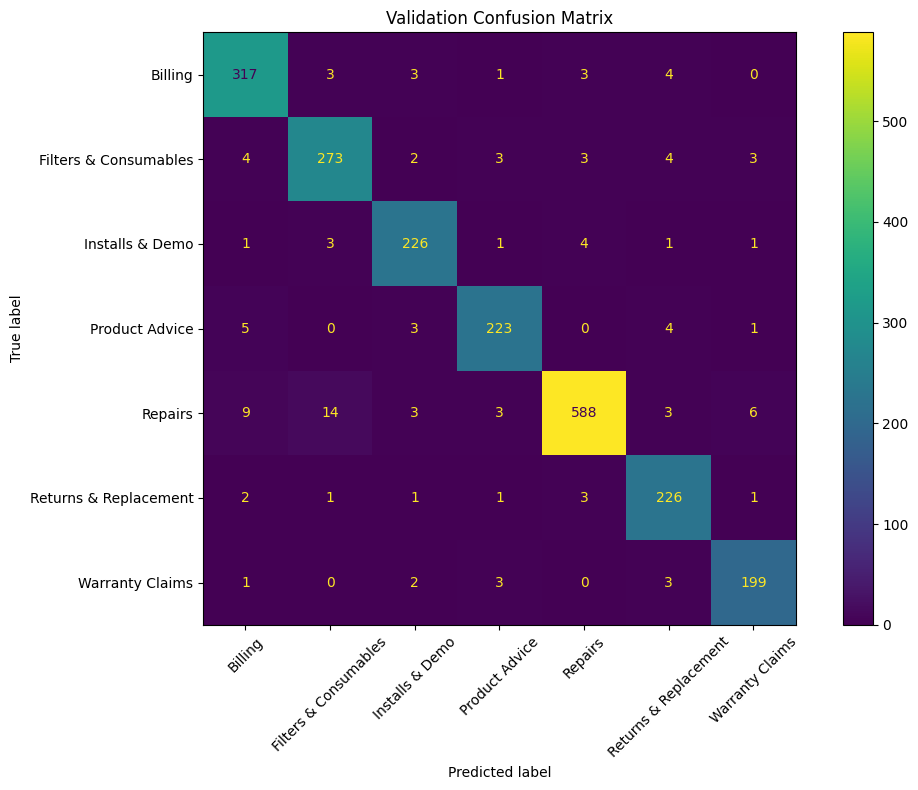

In [34]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

labels = sorted(y_val.unique())

cm = confusion_matrix(
    y_val,
    val_predictions,
    labels=labels
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
)

fig, ax = plt.subplots(figsize=(11, 8))
disp.plot(ax=ax, xticks_rotation=45, values_format="d")
plt.title("Validation Confusion Matrix")
plt.tight_layout()
plt.show()

In [35]:
# Find Repairs requests incorrectly predicted as Filters & Consumables
confused_cases = X_val[
    (y_val == "Repairs")
    & (val_predictions == "Filters & Consumables")
].copy()

confused_cases["actual_team"] = y_val[
    confused_cases.index
]
confused_cases["predicted_team"] = val_predictions[
    X_val.index.get_indexer(confused_cases.index)
]

print("Number of cases:", len(confused_cases))

display(
    confused_cases[
        ["request_text", "product_family",
         "actual_team", "predicted_team"]
    ]
)

Number of cases: 14


,request_text,product_family,actual_team,predicted_team
3241,"namaste, consumable pack for water purifier price very disappointed",Water Purifier,Repairs,Filters & Consumables
1149,"where to buy spare jar for mixer, mixer not turning on",Mixer Grinder,Repairs,Filters & Consumables
3978,"water purifier leaking water from bottom, water purifier leaking water from bottom pls call back",Water Purifier,Repairs,Filters & Consumables
2476,"hello team, purifier showing error code E1",Water Purifier,Repairs,Filters & Consumables
10197,"hi, want AMC filter kit for air fryer, someone contact me about air fryer order KO2606016",Air Fryer,Repairs,Filters & Consumables
8168,sir water purifier showing error code E6 kindly resolve,Water Purifier,Repairs,Filters & Consumables
7685,water purifier not turning on kindly resolve,Water Purifier,Repairs,Filters & Consumables
1948,"pls help - spare blade set for mixer available?, mixer stopped working after 13 months thanks",Robot Vacuum,Repairs,Filters & Consumables
8723,water purifier leaking water from bottom reg no SR46774 purifier not working,Water Purifier,Repairs,Filters & Consumables
4457,"hello team, water purifier making loud noise purifier not working",Water Purifier,Repairs,Filters & Consumables


In [36]:
# Validation cases predicted as Filters & Consumables
filter_predictions = X_val[
    val_predictions == "Filters & Consumables"
].copy()

filter_predictions["actual_team"] = y_val.loc[
    filter_predictions.index
]

filter_predictions["predicted_team"] = "Filters & Consumables"

malfunction_pattern = (
    r"\b(?:not turning on|not working|stopped working|"
    r"leaking|error code|burnt smell|tripping the mcb|"
    r"making loud noise)\b"
)

filter_predictions["mentions_malfunction"] = (
    filter_predictions["request_text"].str.contains(
        malfunction_pattern,
        case=False,
        regex=True,
        na=False
    )
)

malfunction_cases = filter_predictions[
    filter_predictions["mentions_malfunction"]
]

print("Total predictions of Filters & Consumables:",
      len(filter_predictions))

print("Those mentioning malfunction language:",
      len(malfunction_cases))

print("\nActual team distribution among these cases:")
print(malfunction_cases["actual_team"].value_counts())

display(
    malfunction_cases[
        ["request_text", "actual_team", "predicted_team"]
    ].head(20)
)

Total predictions of Filters & Consumables: 294
Those mentioning malfunction language: 61

Actual team distribution among these cases:
actual_team
Filters & Consumables    50
Repairs                  11
Name: count, dtype: int64


,request_text,actual_team,predicted_team
1114,water purifier making loud noise purifier not working,Filters & Consumables,Filters & Consumables
10524,pls help - purifier showing error code E5 purifier not working,Filters & Consumables,Filters & Consumables
5736,motor of water purifier burnt smell pls call back purifier not working,Filters & Consumables,Filters & Consumables
2131,pls help - water purifier making loud noise very disappointed purifier not working,Filters & Consumables,Filters & Consumables
1149,"where to buy spare jar for mixer, mixer not turning on",Repairs,Filters & Consumables
880,sir purifier tripping the mcb very disappointed purifier not working,Filters & Consumables,Filters & Consumables
894,"hello team, water purifier making loud noise purifier not working",Filters & Consumables,Filters & Consumables
3265,product stopped working after 2 months,Filters & Consumables,Filters & Consumables
5825,"namaste, need installation for my new water purifier, water purifier leaking water from bottom order KO2610153 purifier not working",Filters & Consumables,Filters & Consumables
3978,"water purifier leaking water from bottom, water purifier leaking water from bottom pls call back",Repairs,Filters & Consumables


In [37]:
import numpy as np
from sklearn.metrics import accuracy_score, classification_report

val_text = X_val["request_text"].str.lower()

# Clear malfunction terms
malfunction_pattern = (
    r"\b(?:not turning on|not working|stopped working|"
    r"leaking|error code|burnt smell|tripping the mcb|"
    r"making loud noise|display.*blank)\b"
)

# Explicit consumable / spare-part terms
parts_pattern = (
    r"\b(?:filter|filters|membrane|candle|consumable|"
    r"spare|blade|jar|amc kit)\b"
)

is_filter_prediction = (
    val_predictions == "Filters & Consumables"
)

has_malfunction = val_text.str.contains(
    malfunction_pattern, regex=True, na=False
)

mentions_parts = val_text.str.contains(
    parts_pattern, regex=True, na=False
)

# Candidate correction: only clear malfunctions without parts wording
override_mask = (
    is_filter_prediction
    & has_malfunction
    & ~mentions_parts
)

candidate_predictions = np.array(val_predictions, dtype=object)
candidate_predictions[override_mask.to_numpy()] = "Repairs"

print("Candidate requests changed:", int(override_mask.sum()))
print("Original validation accuracy:",
      round(accuracy_score(y_val, val_predictions), 4))
print("Accuracy after candidate rule:",
      round(accuracy_score(y_val, candidate_predictions), 4))

print("\nCandidate-rule classification report:")
print(classification_report(
    y_val,
    candidate_predictions,
    zero_division=0
))

Candidate requests changed: 57
Original validation accuracy: 0.9478
Accuracy after candidate rule: 0.9298

Candidate-rule classification report:
                       precision    recall  f1-score   support

              Billing       0.94      0.96      0.95       331
Filters & Consumables       0.95      0.77      0.85       292
      Installs & Demo       0.94      0.95      0.95       237
       Product Advice       0.95      0.94      0.95       236
              Repairs       0.91      0.95      0.93       626
Returns & Replacement       0.92      0.96      0.94       235
      Warranty Claims       0.94      0.96      0.95       208

             accuracy                           0.93      2165
            macro avg       0.94      0.93      0.93      2165
         weighted avg       0.93      0.93      0.93      2165



In [38]:
# Confirm the final submission uses the original model
print("Submission rows:", len(final_submission))
print("Unique request IDs:", final_submission["request_id"].nunique())
print("\nPredicted team counts:")
print(final_submission["team"].value_counts())

# Check the required output columns
print("\nColumns:", final_submission.columns.tolist())
print("Missing values:", final_submission.isna().sum().sum())

Submission rows: 2178
Unique request IDs: 2178

Predicted team counts:
team
Repairs                  631
Billing                  341
Filters & Consumables    285
Installs & Demo          244
Returns & Replacement    242
Product Advice           228
Warranty Claims          207
Name: count, dtype: int64

Columns: ['request_id', 'team']
Missing values: 0


In [39]:
final_submission.to_csv("/content/submission.csv", index=False)

from google.colab import files
files.download("/content/submission.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [40]:
# Historical estimated routing costs
transfer_cost = 3902 * 305
contact_cost = 2471 * 260
historical_total_cost = transfer_cost + contact_cost

# Existing annual bot licence
annual_license_cost = 320000

print(f"Transfer cost: ₹{transfer_cost:,.0f}")
print(f"Extra-contact cost: ₹{contact_cost:,.0f}")
print(f"Combined historical estimate: ₹{historical_total_cost:,.0f}")
print(f"Existing annual licence: ₹{annual_license_cost:,.0f}")

Transfer cost: ₹1,190,110
Extra-contact cost: ₹642,460
Combined historical estimate: ₹1,832,570
Existing annual licence: ₹320,000


In [41]:
# Potential savings at different cost-reduction rates
reduction_rates = [0.10, 0.20, 0.30, 0.40]

for rate in reduction_rates:
    transfer_savings = transfer_cost * rate
    contact_savings = contact_cost * rate
    total_savings = transfer_savings + contact_savings

    print(f"\nCost reduction: {rate:.0%}")
    print(f"  Transfer savings: ₹{transfer_savings:,.0f}")
    print(f"  Contact savings: ₹{contact_savings:,.0f}")
    print(f"  Total potential savings: ₹{total_savings:,.0f}")


Cost reduction: 10%
  Transfer savings: ₹119,011
  Contact savings: ₹64,246
  Total potential savings: ₹183,257

Cost reduction: 20%
  Transfer savings: ₹238,022
  Contact savings: ₹128,492
  Total potential savings: ₹366,514

Cost reduction: 30%
  Transfer savings: ₹357,033
  Contact savings: ₹192,738
  Total potential savings: ₹549,771

Cost reduction: 40%
  Transfer savings: ₹476,044
  Contact savings: ₹256,984
  Total potential savings: ₹733,028


In [42]:
# Historical dataset covers April 2025 to June 2026 (15 months)
months_of_data = 15

# Annualize the estimated routing costs
annual_transfer_cost = transfer_cost / months_of_data * 12
annual_contact_cost = contact_cost / months_of_data * 12
annual_total_cost = annual_transfer_cost + annual_contact_cost

print(f"Annualized transfer cost: ₹{annual_transfer_cost:,.0f}")
print(f"Annualized extra-contact cost: ₹{annual_contact_cost:,.0f}")
print(f"Annualized combined cost: ₹{annual_total_cost:,.0f}")

# Compare potential savings against the existing licence
for rate in reduction_rates:
    annual_savings = annual_total_cost * rate
    max_ai_cost = annual_license_cost + annual_savings

    print(f"\nCost reduction: {rate:.0%}")
    print(f"  Annual potential savings: ₹{annual_savings:,.0f}")
    print(f"  Maximum AI annual cost to break even: ₹{max_ai_cost:,.0f}")

Annualized transfer cost: ₹952,088
Annualized extra-contact cost: ₹513,968
Annualized combined cost: ₹1,466,056

Cost reduction: 10%
  Annual potential savings: ₹146,606
  Maximum AI annual cost to break even: ₹466,606

Cost reduction: 20%
  Annual potential savings: ₹293,211
  Maximum AI annual cost to break even: ₹613,211

Cost reduction: 30%
  Annual potential savings: ₹439,817
  Maximum AI annual cost to break even: ₹759,817

Cost reduction: 40%
  Annual potential savings: ₹586,422
  Maximum AI annual cost to break even: ₹906,422


In [43]:
print("Annual net benefit before AI running costs")
print("(Assumes the old licence is fully eliminated)\n")

for rate in reduction_rates:
    annual_savings = annual_total_cost * rate
    net_benefit_before_ai = annual_license_cost + annual_savings

    print(
        f"{rate:.0%} reduction: "
        f"₹{net_benefit_before_ai:,.0f} available per year "
        "for AI costs and net benefit"
    )

Annual net benefit before AI running costs
(Assumes the old licence is fully eliminated)

10% reduction: ₹466,606 available per year for AI costs and net benefit
20% reduction: ₹613,211 available per year for AI costs and net benefit
30% reduction: ₹759,817 available per year for AI costs and net benefit
40% reduction: ₹906,422 available per year for AI costs and net benefit


# Kestrel Home — AI Support Request Routing

## 1. Objective

The objective of this project was to build a machine-learning classifier that predicts the appropriate support team for incoming customer requests. The goal was to reproduce historical routing labels, evaluate classification performance, generate predictions for unlabelled requests, and assess the potential operational and financial benefits of replacing the existing routing bot.

## 2. Data and preparation

The training dataset contained 10,822 labelled requests dated from 1 April 2025 to 30 June 2026. The unlabelled dataset contained 2,178 requests dated from 1 July 2026 onward.

The request text was combined with three categorical features: product family, channel, and warranty status.

An important data-quality issue was a change in team names effective 15 January 2026. The historical labels `Consumables` and `Installations` were standardized to `Filters & Consumables` and `Installs & Demo`, respectively, before model training. This produced seven standardized target classes.

The target was the historical `team_label`, representing the queue assigned when a request was created. It was not the same as `final_team`, which records the team that eventually resolved the request.

## 3. Model development and evaluation

A baseline model used TF-IDF features from request text and logistic regression. After standardizing historical team names, the text-only model achieved 93.44% validation accuracy and a macro F1-score of approximately 0.94.

A second model combined TF-IDF text features with one-hot-encoded product family, channel, and warranty status. Logistic regression was used as the classifier.

Using an 80/20 stratified train-validation split with `random_state=42`, the combined-feature model achieved:

- **Accuracy:** 94.78%
- **Macro F1-score:** approximately 0.95
- **Weighted F1-score:** approximately 0.95

Class-level F1-scores ranged from approximately 0.93 to 0.96 across the seven standardized classes.

The combined-feature model improved on the text-only baseline. The results indicate strong agreement with the standardized historical labels on the held-out validation set. They do not establish that 94.78% of real-world requests will be routed correctly under every operational condition.

## 4. Prediction output

The selected model was retrained using all 10,822 labelled historical requests and used to predict the 2,178 unlabelled requests.

The generated `submission.csv` contains two columns: `request_id` and `team`. It contains 2,178 rows, with 2,178 unique request IDs and no missing values.

The predictions use the seven standardized team labels.

## 5. Operational cost analysis

The resolution log contained 10,822 requests and 3,902 transfer events. At ₹305 per transfer event, the estimated transfer cost was ₹11,90,110.

A total of 2,471 requests had different `first_team` and `final_team` values. Using the supplied average extra-contact cost of ₹260 per such request gives an estimated extra-contact cost of ₹6,42,460.

The combined historical cost estimate was ₹18,32,570. Annualizing this over the 15-month training period gives an estimated annual cost of approximately ₹14,66,056.

These figures are estimates based on the supplied operational assumptions. A difference between the first and final team is only a proxy for a misroute and does not prove that every such request generated an extra contact or that every cost is avoidable.

### Illustrative savings scenarios

| Assumed reduction in routing costs | Annual potential savings | Maximum annual AI cost to break even* |
|---|---:|---:|
| 10% | ₹1,46,606 | ₹4,66,606 |
| 20% | ₹2,93,211 | ₹6,13,211 |
| 30% | ₹4,39,817 | ₹7,59,817 |
| 40% | ₹5,86,422 | ₹9,06,422 |

*The break-even ceiling assumes the existing ₹3,20,000 annual licence is fully eliminated and the assumed routing savings are realized. Actual net benefit must account for AI API usage, infrastructure, monitoring, human review, and maintenance costs.

The scenarios are illustrative rather than measured model savings. Classification accuracy alone does not demonstrate a proportional reduction in transfers or customer contacts.

## 6. Error analysis and experiments

The baseline model performed poorly on the renamed team classes before historical labels were standardized. This showed the importance of investigating changes in team definitions and label consistency before comparing model performance.

A proposed keyword-based override for requests predicted as `Filters & Consumables` was also tested. It reduced validation accuracy from 94.78% to approximately 92.98% and weakened F1-scores for affected classes. The override was therefore rejected in favour of the original combined-feature model.

An audit of requests predicted as Billing found that payment-related wording can occur alongside installation, repair, and warranty issues. A broad rule that routes every request mentioning payment to Billing would be unsafe. Billing should be selected when the payment itself is the issue, in accordance with the supplied operational policy.

## 7. Limitations and recommendations

1. Validate the model in a controlled pilot before replacing the existing routing system.
2. Measure actual transfers, additional customer contacts, and resolution outcomes during the pilot.
3. Confirm the current team taxonomy and monitor performance when labels or routing policies change.
4. Review low-confidence and ambiguous requests, particularly those involving payment alongside installation or repair.
5. Obtain written estimates of AI API, infrastructure, monitoring, and maintenance costs before making a financial decision.
6. Compare realized operational savings and total AI costs against the existing ₹3,20,000 annual licence.

## 8. Conclusion

The combined text-and-categorical-feature model achieved 94.78% validation accuracy against the standardized historical routing labels and generated a structurally valid prediction file for 2,178 unlabelled requests.

The analysis identifies potential financial value, but the actual savings remain unverified. A controlled operational pilot and a complete estimate of AI running costs are needed before recommending full replacement of the existing routing bot.

In [44]:
import os
import pandas as pd

# Check whether the submission file exists
print("File exists:", os.path.exists("/content/submission.csv"))

# Load and inspect the submission
submission_check = pd.read_csv("/content/submission.csv")

print("Shape:", submission_check.shape)
print("Columns:", submission_check.columns.tolist())
print("Missing values:", submission_check.isnull().sum().sum())
print("Unique request IDs:", submission_check["request_id"].nunique())
print("\nPredicted team counts:")
print(submission_check["team"].value_counts())

File exists: True
Shape: (2178, 2)
Columns: ['request_id', 'team']
Missing values: 0
Unique request IDs: 2178

Predicted team counts:
team
Repairs                  640
Billing                  345
Filters & Consumables    274
Returns & Replacement    244
Installs & Demo          241
Product Advice           230
Warranty Claims          204
Name: count, dtype: int64


In [45]:
# Compare the saved CSV with the predictions currently in memory
current_submission = pd.DataFrame({
    "request_id": test_df["request_id"],
    "team": final_predictions
})

saved_submission = pd.read_csv("/content/submission.csv")

comparison = (
    current_submission
    .merge(
        saved_submission,
        on="request_id",
        how="outer",
        suffixes=("_current", "_saved"),
        indicator=True
    )
)

print("All request IDs match:", (comparison["_merge"] == "both").all())
print(
    "Predictions that differ:",
    (comparison["team_current"] != comparison["team_saved"]).sum()
)

All request IDs match: True
Predictions that differ: 37


In [46]:
# Generate final predictions using the selected trained model
X_unlabelled = test_df[
    ["request_text", "product_family", "channel", "warranty_status"]
]

final_predictions = model_features.predict(X_unlabelled)

# Create and save the final submission
final_submission = pd.DataFrame({
    "request_id": test_df["request_id"],
    "team": final_predictions
})

final_submission.to_csv("/content/submission.csv", index=False)

# Reload and verify
check = pd.read_csv("/content/submission.csv")

print("Shape:", check.shape)
print("Columns:", check.columns.tolist())
print("Missing values:", check.isnull().sum().sum())
print("Unique IDs:", check["request_id"].nunique())
print("Predictions match current model:",
      (check["team"].to_numpy() == final_predictions).all())

Shape: (2178, 2)
Columns: ['request_id', 'team']
Missing values: 0
Unique IDs: 2178
Predictions match current model: True
